In [1]:
no_of_threads = "12"

import os
os.environ["VECLIB_MAXIMUM_THREADS"] = no_of_threads
os.environ["OMP_NUM_THREADS"] = no_of_threads


In [2]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [3]:
B=2 #Batchsize

In [4]:


import torch
from torch import linalg as LA
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import time
import statistics
from typing import Tuple
from typing_extensions import Annotated
import transformers
import psutil

from transformers import AutoModelForCausalLM, AutoTokenizer
import json
import platform
import subprocess
import time
from datasets import load_dataset
import re

In [5]:
arc = load_dataset("allenai/ai2_arc", "ARC-Challenge", split="test")

In [6]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
REVISION = "989aa7980e4cf806f80c7fef2b1adb7bc71aa306"   

#model_hf = AutoModelForCausalLM.from_pretrained(
#    MODEL_ID, revision=REVISION, dtype=torch.float32, device_map="cpu"
#)

model_hf = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, dtype=torch.float32
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)

W1026 22:54:45.344000 1381 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

In [7]:


def extract_letter(text):
    # try the most explicit patterns first, so a leading article "A" isn't read as the answer
    for pat in (r"answer is\s*:?\s*\(?([A-E1-5])\b",   # "the answer is C"
                r"^\s*\(?([A-E1-5])[\).:]",           # "C. ..." or "(C)" at the start of a line
                r"\b([A-E1-5])[\).]"):                # "C." / "C)" anywhere
        m = re.search(pat, text, re.I | re.M)
        if m:
            return m.group(1).upper()
    return None

tokenizer.padding_side = "left"
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def time_counter(no_of_threads: int, model, tokenizer, prompts: list, results: list,
                 answer_keys: list = None, max_new_tokens: int = 128,
                 batch_size: int = B, repeats: int = 3):

    torch.set_num_threads(int(no_of_threads))
    print("threads:", torch.get_num_threads())
    time.sleep(2)
    proc = psutil.Process(os.getpid())

    for start in range(0, len(prompts), batch_size):
        ids = list(range(start, min(start + batch_size, len(prompts))))
        texts = [tokenizer.apply_chat_template([{"role": "user", "content": prompts[i]}],
                                               tokenize=False, add_generation_prompt=True)
                 for i in ids]
        
        
        model_inputs = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
        print(model_inputs["input_ids"][:, :5])
        print(tokenizer.pad_token_id)
        input_len = model_inputs["input_ids"].shape[1]

        with torch.inference_mode():
            # warm-up (not timed)
            model.generate(**model_inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.pad_token_id)

            n_lst = []
            for i in range(repeats):
                start_time = time.perf_counter()
                out_put_ids = model.generate(**model_inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.pad_token_id)
                end_time = time.perf_counter()
                n_lst.append(end_time - start_time)

        mean = statistics.mean(n_lst)
        stndev = statistics.stdev(n_lst) if len(n_lst) > 1 else 0.0
        mem_gb = proc.memory_info().rss / 1e9
        gen = out_put_ids[:, input_len:]
        n_new = (gen != tokenizer.pad_token_id).sum(dim=1).tolist()
        for row, pid in enumerate(ids):
            answer = tokenizer.decode(gen[row], skip_special_tokens=True)
            letter = extract_letter(answer)
            n_dict = {
                'thread': torch.get_num_threads(),
                'batch_size': batch_size,
                'batch_start': start,
                'prompt_id': pid,
                'batch_mean': mean,
                'batch_stdev': stndev,
                'input_tokens': input_len,
                'new_tokens': n_new[row],
                'mem_gb': mem_gb,
                'answer': answer,
                'pred': letter,
            }
            if answer_keys is not None:
                n_dict['key'] = answer_keys[pid]
                n_dict['correct'] = (letter == answer_keys[pid])
            results.append(n_dict)


        

In [8]:
def make_prompt(item):
    lines = [item["question"]]
    for label, text in zip(item["choices"]["label"], item["choices"]["text"]):
        lines.append(f"{label}. {text}")
    lines.append("Answer with the letter and briefly explain why.")
    return "\n".join(lines)





In [9]:
results = []
prompts = [make_prompt(arc[i]) for i in range(32)]
answer_keys = [arc[i]["answerKey"] for i in range(32)]

with open("prompts_arc32.json", "w") as f:
    json.dump({"prompts": prompts, "answer_keys": answer_keys}, f, indent=2)

with open("prompts_arc32.json") as f:
    data = json.load(f)
prompts, answer_keys = data["prompts"], data["answer_keys"]
print(len(prompts), len(answer_keys))   # 32 32

32 32


In [10]:


run_name = datetime.now().strftime("openblas_32p_%Y%m%d_%H%M")  
csv_file = f"{run_name}.csv"
print("saving to", csv_file)

results = []

for t in range(1,13):
    time_counter(t, model_hf, tokenizer, prompts, results, answer_keys=answer_keys)
    pd.DataFrame(results).to_csv(csv_file, index=False)
    print("saved after", t, "threads,", len(results), "rows")
    

saving to openblas_32p_20261026_2254.csv
threads: 1
tensor([[151643, 151643, 151643, 151643, 151643],
        [151644,   8948,    198,   2610,    525]])
151643
tensor([[151643, 151643, 151643, 151643, 151643],
        [151644,   8948,    198,   2610,    525]])
151643
tensor([[151643, 151643, 151643, 151643, 151644],
        [151644,   8948,    198,   2610,    525]])
151643
tensor([[151644,   8948,    198,   2610,    525],
        [151643, 151643, 151643, 151643, 151643]])
151643
tensor([[151644,   8948,    198,   2610,    525],
        [151643, 151643, 151643, 151643, 151643]])
151643
tensor([[151644,   8948,    198,   2610,    525],
        [151643, 151643, 151643, 151643, 151643]])
151643
tensor([[151644,   8948,    198,   2610,    525],
        [151643, 151643, 151643, 151643, 151643]])
151643
tensor([[151643, 151643, 151643, 151643, 151643],
        [151644,   8948,    198,   2610,    525]])
151643
tensor([[151644,   8948,    198,   2610,    525],
        [151643, 151643, 151643, 1

In [11]:
results

[{'thread': 1,
  'batch_size': 2,
  'batch_start': 0,
  'prompt_id': 0,
  'batch_mean': 61.11088491666791,
  'batch_stdev': 0.7398689590393897,
  'input_tokens': 115,
  'new_tokens': 128,
  'mem_gb': 6.987956224,
  'answer': "The correct answer is C: Planetary days will become shorter.\n\nExplanation:\nWhen a meteorite impacts a planet, it can cause significant changes to its surface structure and composition. The increased friction from the impact could lead to more frequent collisions between rocks on the planet's surface, which would result in shorter days as the planet slows down due to these collisions. This process is known as tidal locking or synchronous rotation, where one side of the planet always faces the sun, leading to shorter days for that side compared to the other side facing away from the sun.\n\nOptions A (Planetary density will decrease) and B (Planetary years will become",
  'pred': 'C',
  'key': 'C',
  'correct': True},
 {'thread': 1,
  'batch_size': 2,
  'batch_st

In [12]:
print(torch.__config__.show())

PyTorch built with:
  - GCC 4.2
  - C++ Version: 202002
  - clang 21.1.8
  - OpenMP 202011
  - LAPACK is enabled (usually provided by MKL)
  - NNPACK is enabled
  - CPU capability usage: DEFAULT
  - Build settings: BLAS_INFO=open, BUILD_TYPE=Release, COMMIT_SHA=Unknown, CUDA_FLAGS= -DLIBCUDACXX_ENABLE_SIMPLIFIED_COMPLEX_OPERATIONS -Xfatbin -compress-all  -Wno-deprecated-gpu-targets --expt-extended-lambda -DCUB_WRAPPED_NAMESPACE=at_cuda_detail -DDISABLE_CUSPARSE_DEPRECATED -DCUDA_HAS_FP16=1 -D__CUDA_NO_HALF_OPERATORS__ -D__CUDA_NO_HALF_CONVERSIONS__ -D__CUDA_NO_HALF2_OPERATORS__ -D__CUDA_NO_BFLOAT16_CONVERSIONS__ -DC10_NODEPRECATED, CXX_COMPILER=/Users/runner/miniforge3/conda-bld/libtorch_1791585336308/_build_env/bin/arm64-apple-darwin20.0.0-clang++, CXX_FLAGS=-ftree-vectorize -fPIC -fstack-protector-strong -O2 -pipe -stdlib=libc++  -fmessage-length=0 -isystem /Users/runner/miniforge3/conda-bld/libtorch_1791585336308/_h_env_placehold_placehold_placehold_placehold_placehold_placehold_pla

In [13]:
df = pd.DataFrame(results)
per_batch = df.drop_duplicates(["thread", "batch_start"])        # one row per batch
total = per_batch.groupby("thread")["batch_mean"].sum()          # seconds for all prompts
t1 = total.loc[1]

n_res = []
for n, t in total.items():
    speedup = t1 / t
    n_res.append({
        "threads": n,
        "mean": t,
        "speedup": speedup,
        "efficiency": speedup / n * 100,
        "serial_fraction": ((n / speedup - 1) / (n - 1)) * 100 if n > 1 else None,
    })

In [14]:
n_res

[{'threads': 1,
  'mean': 964.2092803056585,
  'speedup': np.float64(1.0),
  'efficiency': np.float64(100.0),
  'serial_fraction': None},
 {'threads': 2,
  'mean': 645.0132070277177,
  'speedup': np.float64(1.4948675000762026),
  'efficiency': np.float64(74.74337500381013),
  'serial_fraction': np.float64(33.79112194880467)},
 {'threads': 3,
  'mean': 648.0395966796301,
  'speedup': np.float64(1.487886365657271),
  'efficiency': np.float64(49.5962121885757),
  'serial_fraction': np.float64(50.81415050385101)},
 {'threads': 4,
  'mean': 650.8825222370311,
  'speedup': np.float64(1.4813875735850892),
  'efficiency': np.float64(37.03468933962723),
  'serial_fraction': np.float64(56.67237193301694)},
 {'threads': 5,
  'mean': 652.0438473600079,
  'speedup': np.float64(1.4787491427295028),
  'efficiency': np.float64(29.574982854590054),
  'serial_fraction': np.float64(59.5309027664237)},
 {'threads': 6,
  'mean': 653.8890955953199,
  'speedup': np.float64(1.4745761732390017),
  'efficiency'

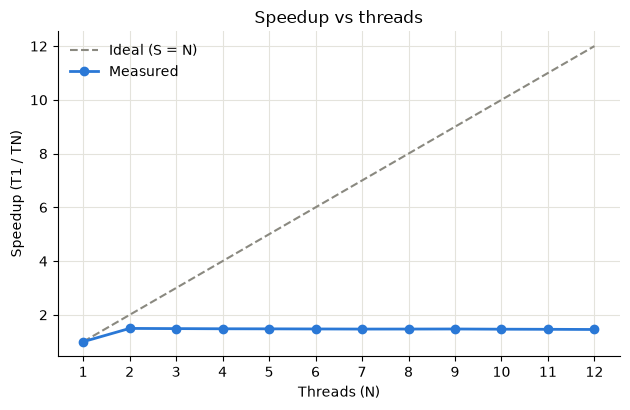

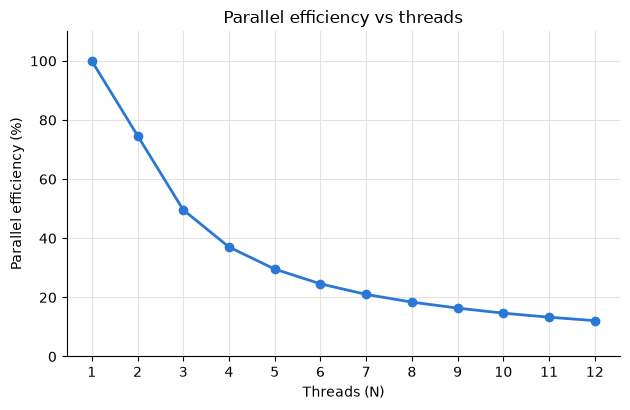

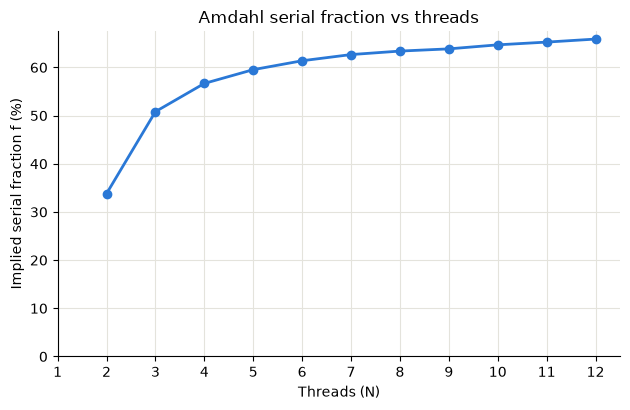

In [15]:


RUN_NAME = "run5 batch 2"   # change per run, used in the file names

threads = [r["threads"] for r in n_res]
speedup = [r["speedup"] for r in n_res]
efficiency = [r["efficiency"] for r in n_res]
# Amdahl serial fraction (%), skipping 1 thread
f_threads = [n for n in threads if n > 1]
serial = [((n / s) - 1) / (n - 1) * 100 for n, s in zip(threads, speedup) if n > 1]

BLUE, GREY = "#2a78d6", "#8a8980"

def tidy(ax, ylabel, title):
    ax.set_xlabel("Threads (N)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(threads)
    ax.grid(True, color="#e4e3dc")
    ax.spines[["top", "right"]].set_visible(False)

# 1. Speedup vs ideal
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, threads, "--", color=GREY, label="Ideal (S = N)")
ax.plot(threads, speedup, "o-", color=BLUE, linewidth=2, label="Measured")
tidy(ax, "Speedup (T1 / TN)", "Speedup vs threads")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{RUN_NAME}_speedup.png", dpi=200); plt.show()

# 2. Efficiency
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, efficiency, "o-", color=BLUE, linewidth=2)
ax.set_ylim(0, 110)
tidy(ax, "Parallel efficiency (%)", "Parallel efficiency vs threads")
fig.tight_layout(); fig.savefig(f"{RUN_NAME}_efficiency.png", dpi=200); plt.show()

# 3. Serial fraction
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(f_threads, serial, "o-", color=BLUE, linewidth=2)
ax.set_ylim(bottom=0)
tidy(ax, "Implied serial fraction f (%)", "Amdahl serial fraction vs threads")
fig.tight_layout(); fig.savefig(f"{RUN_NAME}_serial_fraction.png", dpi=200); plt.show()

In [16]:
import torch, time
torch.set_num_threads(2)
W = torch.randn(8960, 1536)                  # one MLP weight matrix of Qwen2.5-1.5B
for B in [1, 2, 4, 8, 16, 32]:
    x = torch.randn(B, 1536)
    for _ in range(5): x @ W.T              # warm-up
    t0 = time.perf_counter()
    for _ in range(200): x @ W.T
    dt = (time.perf_counter() - t0) / 200
    print(f"B={B:2d}  {dt*1e3:7.3f} ms   per row {dt*1e3/B:7.3f} ms")

B= 1    0.471 ms   per row   0.471 ms
B= 2    2.537 ms   per row   1.268 ms
B= 4    3.881 ms   per row   0.970 ms
B= 8    3.156 ms   per row   0.394 ms
B=16    3.315 ms   per row   0.207 ms
B=32    5.391 ms   per row   0.168 ms


In [ ]:
'''
Experiment log: Qwen2.5-1.5B-Instruct, M3 Pro, PyTorch 2.14.1 (conda-forge, OpenBLAS), FP32
Run 1: thread sweep, batch 1 (OpenBLAS)
32 ARC-Challenge prompts, threads 1 to 12, 3 repeats + warm-up per prompt, overnight.
1 thread: 462.9 s total; 2 threads: 269.2 s (best); 12 threads: 284.9 s.
Peak speedup 1.72× at 2 threads, then a slow decline; efficiency 14% at 12 threads.
Serial fraction rises from 16% (2 threads) to 58% (12 threads), so not constant: not pure Amdahl.
3,498 generated tokens at every thread count.
Answers identical across all 12 thread counts (text, token count, letter).
Matches the earlier timing-only run (1.716× at 2 threads), so reproducible.
Run 2: thread sweep, batch 2 (OpenBLAS)
Same prompts, threads 1 to 12.
1 thread: 964.2 s; 2 threads: 645.0 s; 12 threads: 662.6 s.
2.1 to 2.4× slower than batch 1 at every thread count.
Condition: Notes app open during the run.
To check: total new_tokens (expect about 3,498) and answer consistency with batch 1.
Test A: matrix-multiply microbenchmark (one 8960 × 1536 weight, 2 threads, 200 repeats)


'''